<a href="https://colab.research.google.com/github/SrustiUB/Data-Science/blob/main/Hawkess_process.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ==========================================================
# HAWKES PROCESS FOR LARGE LIQUIDITY SHOCK EVENTS
# PART 1
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from scipy.optimize import minimize

# ==========================================================
# STEP 1 : Upload Dataset
# ==========================================================

uploaded = files.upload()

filename = list(uploaded.keys())[0]

depth = pd.read_csv(filename)

print("Dataset Shape :", depth.shape)

# ==========================================================
# STEP 2 : Timestamp
# ==========================================================

depth["timestamp"] = pd.to_datetime(depth["timestamp"])

depth = depth.sort_values("timestamp").reset_index(drop=True)

# ==========================================================
# STEP 3 : Compute Level-10 Liquidity
# ==========================================================

bid_cols = [
    "bid_qty_1","bid_qty_2","bid_qty_3","bid_qty_4","bid_qty_5",
    "bid_qty_6","bid_qty_7","bid_qty_8","bid_qty_9","bid_qty_10"
]

ask_cols = [
    "ask_qty_1","ask_qty_2","ask_qty_3","ask_qty_4","ask_qty_5",
    "ask_qty_6","ask_qty_7","ask_qty_8","ask_qty_9","ask_qty_10"
]

depth["total_bid_liquidity"] = depth[bid_cols].sum(axis=1)

depth["total_ask_liquidity"] = depth[ask_cols].sum(axis=1)

print(depth[["total_bid_liquidity",
             "total_ask_liquidity"]].head())

# ==========================================================
# STEP 4 : Percentage Liquidity Change
# ==========================================================

depth["bid_change"] = (
    depth["total_bid_liquidity"]
    .pct_change()
)

depth["ask_change"] = (
    depth["total_ask_liquidity"]
    .pct_change()
)

depth = depth.dropna().reset_index(drop=True)

# ==========================================================
# STEP 5 : Define Liquidity Shock Events
# ==========================================================

bid_threshold = np.quantile(
    np.abs(depth["bid_change"]),
    0.95
)

ask_threshold = np.quantile(
    np.abs(depth["ask_change"]),
    0.95
)

print("Bid Threshold :", bid_threshold)
print("Ask Threshold :", ask_threshold)

depth["shock_event"] = (

    (np.abs(depth["bid_change"]) > bid_threshold)

    |

    (np.abs(depth["ask_change"]) > ask_threshold)

).astype(int)

events = depth[
    depth["shock_event"] == 1
].copy()

print("\nNumber of Liquidity Shock Events :", len(events))

# ==========================================================
# STEP 6 : Event Times
# ==========================================================

event_times = (
    events["timestamp"] -
    depth["timestamp"].iloc[0]
).dt.total_seconds().values

T = event_times[-1]

print("Observation Time :", T)

# ==========================================================
# STEP 7 : Recursive Hawkes Log-Likelihood
# ==========================================================

def negative_log_likelihood(params):

    mu, alpha, beta = params

    if mu <= 0 or alpha <= 0 or beta <= 0:
        return np.inf

    n = len(event_times)

    R = np.zeros(n)

    for i in range(1, n):

        dt = event_times[i] - event_times[i-1]

        R[i] = np.exp(-beta * dt) * (1 + R[i-1])

    intensity = mu + alpha * R

    if np.any(intensity <= 0):
        return np.inf

    loglik = np.sum(np.log(intensity))

    compensator = (

        mu * T +

        (alpha / beta) *

        np.sum(

            1 -

            np.exp(

                -beta *

                (T - event_times)

            )

        )

    )

    return -(loglik - compensator)

# ==========================================================
# STEP 8 : Estimate Hawkes Parameters
# ==========================================================

result = minimize(

    negative_log_likelihood,

    x0=[0.10, 0.20, 1.00],

    method="L-BFGS-B",

    bounds=[
        (1e-6, None),
        (1e-6, None),
        (1e-6, None)
    ]

)

mu_hat, alpha_hat, beta_hat = result.x

print("\n==============================")
print("Optimization Results")
print("==============================")

print("Success :", result.success)
print("Message :", result.message)

print("\nEstimated Parameters")
print("------------------------------")

print(f"μ (Baseline)   : {mu_hat:.6f}")
print(f"α (Excitation) : {alpha_hat:.6f}")
print(f"β (Decay)      : {beta_hat:.6f}")

Saving BTCUSDT_Depth_1Hour.csv to BTCUSDT_Depth_1Hour.csv
Dataset Shape : (35901, 45)
   total_bid_liquidity  total_ask_liquidity
0              3.36178              0.04791
1             11.37280              0.00000
2              4.84003             53.08928
3              4.28629             50.26274
4              3.89660             51.59063
Bid Threshold : 107.90586277473192
Ask Threshold : 31849.50461538424

Number of Liquidity Shock Events : 828
Observation Time : 3596.775

Optimization Results
Success : True
Message : CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH

Estimated Parameters
------------------------------
μ (Baseline)   : 0.191406
α (Excitation) : 0.093072
β (Decay)      : 0.551532


Hawkes intensity computed successfully.
Poisson Intensity : 0.23020622641115998
             Metric        Value
0  Number of Events   828.000000
1  Observation Time  3596.775000
2       Estimated μ     0.191406
3       Estimated α     0.093072
4       Estimated β     0.551532
5         Poisson λ     0.230206


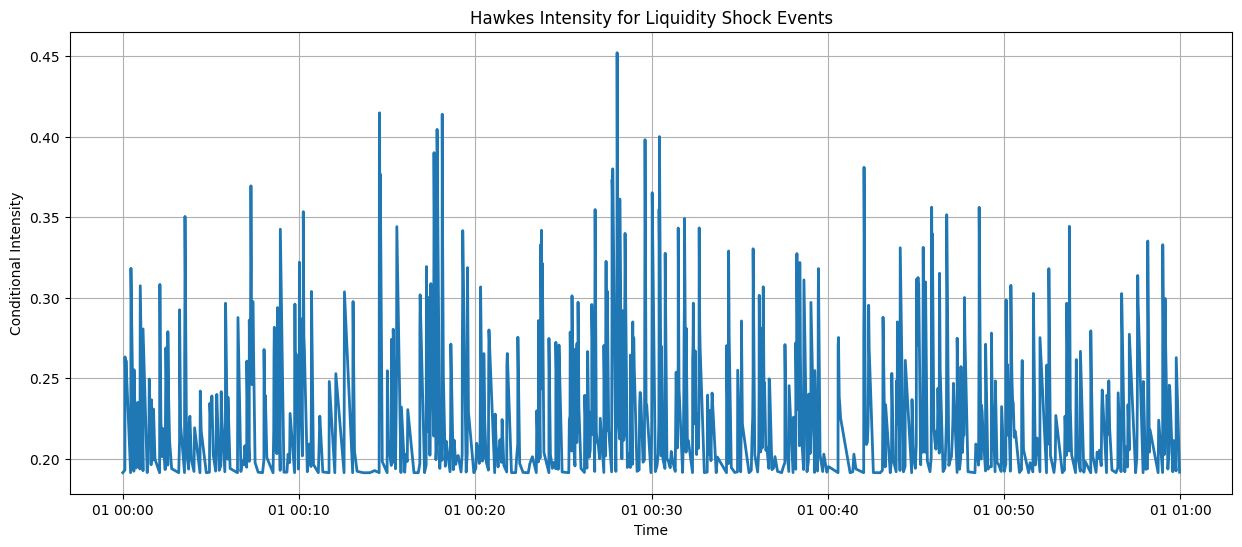

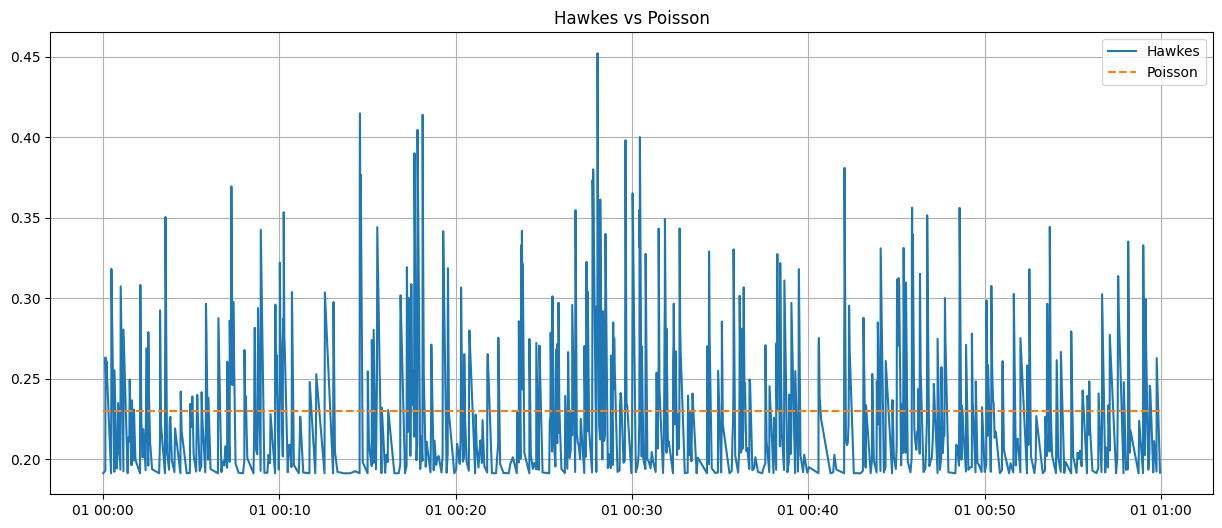

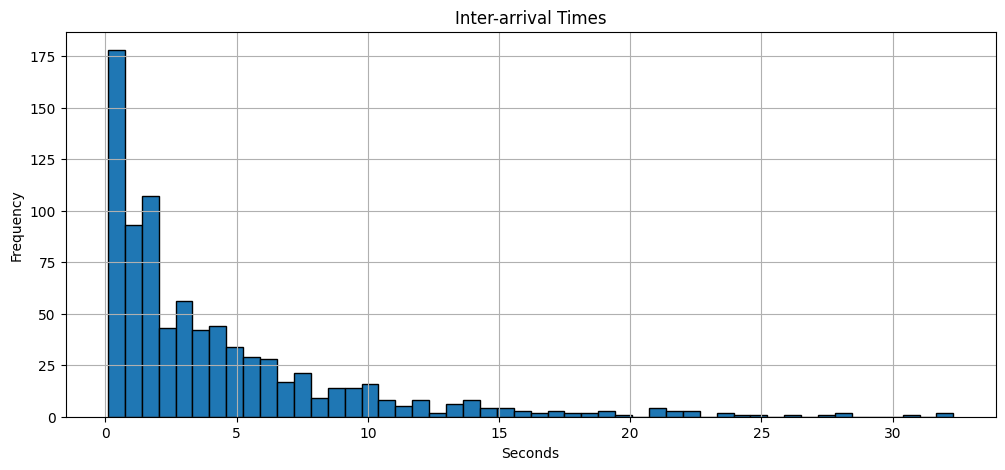


MODEL COMPARISON
     Model  LogLikelihood          AIC          BIC
0  Poisson   -2044.149621  4090.299242  4095.018255
1   Hawkes   -2029.918015  4065.836030  4079.993069

Likelihood Ratio Statistic : 28.46321174737477

Branching Ratio (α/β): 0.16875209499123048

INTERPRETATION
✓ Stable Hawkes process (branching ratio < 1)
✓ Hawkes model outperforms Poisson based on AIC.
✓ Hawkes model outperforms Poisson based on BIC.
✓ Hawkes model is statistically superior according to the Likelihood Ratio Test.

Mini Project 5 Completed Successfully.


In [ ]:
# ==========================================================
# PART 2
# HAWKES INTENSITY
# ==========================================================

n = len(event_times)

R = np.zeros(n)

hawkes_intensity = np.zeros(n)

hawkes_intensity[0] = mu_hat

for i in range(1, n):

    dt = event_times[i] - event_times[i-1]

    R[i] = np.exp(-beta_hat * dt) * (1 + R[i-1])

    hawkes_intensity[i] = mu_hat + alpha_hat * R[i]

events["hawkes_intensity"] = hawkes_intensity

print("Hawkes intensity computed successfully.")

# ==========================================================
# POISSON MODEL
# ==========================================================

poisson_lambda = len(event_times) / T

events["poisson_intensity"] = poisson_lambda

print("Poisson Intensity :", poisson_lambda)

# ==========================================================
# SUMMARY
# ==========================================================

summary = pd.DataFrame({

    "Metric":[
        "Number of Events",
        "Observation Time",
        "Estimated μ",
        "Estimated α",
        "Estimated β",
        "Poisson λ"
    ],

    "Value":[
        len(event_times),
        T,
        mu_hat,
        alpha_hat,
        beta_hat,
        poisson_lambda
    ]

})

print(summary)

# ==========================================================
# HAWKES INTENSITY PLOT
# ==========================================================

plt.figure(figsize=(15,6))

plt.plot(
    events["timestamp"],
    events["hawkes_intensity"],
    linewidth=2
)

plt.title("Hawkes Intensity for Liquidity Shock Events")

plt.xlabel("Time")

plt.ylabel("Conditional Intensity")

plt.grid(True)

plt.show()

# ==========================================================
# HAWKES VS POISSON
# ==========================================================

plt.figure(figsize=(15,6))

plt.plot(
    events["timestamp"],
    events["hawkes_intensity"],
    label="Hawkes"
)

plt.plot(
    events["timestamp"],
    events["poisson_intensity"],
    "--",
    label="Poisson"
)

plt.legend()

plt.grid(True)

plt.title("Hawkes vs Poisson")

plt.show()

# ==========================================================
# INTER-ARRIVAL TIMES
# ==========================================================

plt.figure(figsize=(12,5))

plt.hist(
    np.diff(event_times),
    bins=50,
    edgecolor="black"
)

plt.title("Inter-arrival Times")

plt.xlabel("Seconds")

plt.ylabel("Frequency")

plt.grid(True)

plt.show()

# ==========================================================
# MODEL COMPARISON
# ==========================================================

R = np.zeros(n)

for i in range(1, n):

    dt = event_times[i] - event_times[i-1]

    R[i] = np.exp(-beta_hat * dt) * (1 + R[i-1])

hawkes_intensity = mu_hat + alpha_hat * R

hawkes_loglik = np.sum(np.log(hawkes_intensity))

hawkes_loglik -= (

    mu_hat * T +

    (alpha_hat / beta_hat) *

    np.sum(

        1 -

        np.exp(

            -beta_hat *

            (T - event_times)

        )

    )

)

lambda_hat = len(event_times) / T

poisson_loglik = (

    len(event_times) *

    np.log(lambda_hat)

    -

    lambda_hat * T

)

hawkes_aic = 2*3 - 2*hawkes_loglik

poisson_aic = 2*1 - 2*poisson_loglik

hawkes_bic = np.log(len(event_times))*3 - 2*hawkes_loglik

poisson_bic = np.log(len(event_times))*1 - 2*poisson_loglik

lrt = 2*(hawkes_loglik - poisson_loglik)

comparison = pd.DataFrame({

    "Model":[
        "Poisson",
        "Hawkes"
    ],

    "LogLikelihood":[
        poisson_loglik,
        hawkes_loglik
    ],

    "AIC":[
        poisson_aic,
        hawkes_aic
    ],

    "BIC":[
        poisson_bic,
        hawkes_bic
    ]

})

print("\n==============================")
print("MODEL COMPARISON")
print("==============================")

print(comparison)

print("\nLikelihood Ratio Statistic :", lrt)

# ==========================================================
# BRANCHING RATIO
# ==========================================================

branching_ratio = alpha_hat / beta_hat

print("\nBranching Ratio (α/β):", branching_ratio)

# ==========================================================
# INTERPRETATION
# ==========================================================

print("\n==============================")
print("INTERPRETATION")
print("==============================")

if branching_ratio < 1:
    print("✓ Stable Hawkes process (branching ratio < 1)")
else:
    print("⚠ Unstable Hawkes process (branching ratio ≥ 1)")

if hawkes_aic < poisson_aic:
    print("✓ Hawkes model outperforms Poisson based on AIC.")

if hawkes_bic < poisson_bic:
    print("✓ Hawkes model outperforms Poisson based on BIC.")

if lrt > 3.84:
    print("✓ Hawkes model is statistically superior according to the Likelihood Ratio Test.")

print("\nMini Project 5 Completed Successfully.")